# 01c - OpenAQ Station Data (replaces notebook 01 / 01b)
Uses your OpenAQ export (`data/raw/openaq_location_5542_measurments.csv`, CPCB station, hourly readings in *long* format: one row = one pollutant at one hour).

Steps: read -> one column per pollutant -> hourly to daily -> **CPCB AQI** -> download matching weather for the station's coordinates -> save in the same format notebooks 02-06 expect.

**Before running:** in `utils.py` set `CITY` to your station's city (e.g. `"Jalandhar"`) and add its coordinates to `CITY_COORDS` - see the instructions I sent. Restart the kernel after editing `utils.py`.

In [8]:
import requests
import numpy as np
import pandas as pd
from utils import *

files = sorted(RAW_DIR.glob("openaq*.csv"))
assert files, f"No openaq*.csv file found in {RAW_DIR}"
f = files[0]
print("Reading:", f.name)
try:
    raw = pd.read_csv(f)
except UnicodeDecodeError:
    raw = pd.read_csv(f, encoding="latin-1")

print(raw.shape)
print(raw.columns.tolist())
print("Station:", raw["location_name"].iloc[0] if "location_name" in raw else "?")
lat, lon = float(raw["latitude"].iloc[0]), float(raw["longitude"].iloc[0])
print("Coordinates:", lat, lon)

Reading: openaq_location_5542_measurments.csv
(15738, 15)
['location_id', 'location_name', 'parameter', 'value', 'unit', 'datetimeUtc', 'datetimeLocal', 'timezone', 'latitude', 'longitude', 'country_iso', 'isMobile', 'isMonitor', 'owner_name', 'provider']
Station: Civil Line, Jalandhar - PPCB
Coordinates: 31.321907 75.578914


### What does the station measure, and in which units?

In [9]:
raw["parameter"] = raw["parameter"].astype(str).str.lower().str.strip()
summary = raw.groupby("parameter").agg(readings=("value", "size"),
                                       unit=("unit", lambda s: s.mode().iloc[0]),
                                       mean=("value", "mean"))
print(summary.round(1))

                  readings   unit   mean
parameter                               
co                    1623    ppb  311.6
no                    1000    ppb    8.6
no2                   1622    ppb   24.0
nox                   1000    ppb    0.0
o3                    1623  µg/m³   28.5
pm10                  1624  µg/m³   71.0
pm25                  1622  µg/m³   33.2
relativehumidity      1000      %   74.1
so2                   1624    ppb   15.7
temperature           1000      c   20.9
wind_direction        1000    deg  123.6
wind_speed            1000    m/s    1.5


### Hourly table
Names are mapped to the project's names. If a gas is reported in **ppm**, it is converted to ug/m3 (at 25 C). Negative values are removed.

In [10]:
NAME_MAP = {"pm25": "PM2.5", "pm2.5": "PM2.5", "pm10": "PM10", "no2": "NO2",
            "so2": "SO2", "co": "CO", "o3": "O3"}
PPM_TO_UGM3 = {"NO2": 1880.0, "SO2": 2620.0, "O3": 1960.0, "CO": 1145.0}   # at 25 C, 1 atm

t_col = next(c for c in raw.columns if c.lower().startswith("datetimeutc"))
raw["time"] = (pd.to_datetime(raw[t_col], utc=True)
               .dt.tz_convert("Asia/Kolkata").dt.tz_localize(None).dt.floor("h"))

d = raw[raw["parameter"].isin(NAME_MAP)].copy()
d["pollutant"] = d["parameter"].map(NAME_MAP)
d = d[d["value"] >= 0]
is_ppm = d["unit"].astype(str).str.lower().str.contains("ppm")
d.loc[is_ppm, "value"] = d.loc[is_ppm, "value"] * d.loc[is_ppm, "pollutant"].map(PPM_TO_UGM3)

hourly = d.pivot_table(index="time", columns="pollutant", values="value", aggfunc="mean")
hourly = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h"))
for p in POLLUTANTS:
    if p not in hourly:
        hourly[p] = np.nan
print("Hourly rows:", len(hourly), "|", hourly.index.min(), "->", hourly.index.max())
hourly.head()

Hourly rows: 21629 | 2022-09-13 16:00:00 -> 2025-03-02 20:00:00


pollutant,CO,NO2,O3,PM10,PM2.5,SO2
2022-09-13 16:00:00,590.0,15.57,50.08,85.28,27.27,12.96
2022-09-13 17:00:00,650.0,16.94,38.88,89.36,35.21,14.33
2022-09-13 18:00:00,750.0,13.83,52.61,86.52,31.33,16.45
2022-09-13 19:00:00,820.0,23.54,61.70,90.11,31.61,17.96
2022-09-13 20:00:00,1080.0,22.66,39.17,86.51,26.02,23.83


## Hourly -> daily -> CPCB AQI
* PM2.5, PM10, NO2, SO2: 24-hour average, only if at least **16 hours** of data (CPCB rule)
* CO (converted to mg/m3) and O3: highest 8-hour average of the day
* AQI = highest sub-index among the pollutants (needs PM2.5 or PM10, plus at least 3 pollutants in total)

In [11]:
hourly["CO"] = hourly["CO"] / 1000.0       # ug/m3 -> mg/m3

grp = hourly.resample("D")
daily = grp[["PM2.5", "PM10", "NO2", "SO2"]].mean()
for p in ["PM2.5", "PM10", "NO2", "SO2"]:
    daily.loc[grp[p].count() < 16, p] = np.nan
daily["CO"] = hourly["CO"].rolling(8, min_periods=6).mean().resample("D").max()
daily["O3"] = hourly["O3"].rolling(8, min_periods=6).mean().resample("D").max()

AQI_POINTS = [0, 50, 100, 200, 300, 400, 500]
BREAKS = {
    "PM2.5": [0, 30, 60, 90, 120, 250, 380],
    "PM10":  [0, 50, 100, 250, 350, 430, 510],
    "NO2":   [0, 40, 80, 180, 280, 400, 520],
    "SO2":   [0, 40, 80, 380, 800, 1600, 2100],
    "CO":    [0, 1, 2, 10, 17, 34, 50],
    "O3":    [0, 50, 100, 168, 208, 748, 1000],
}

def cpcb_aqi(row):
    subs = {p: np.interp(row[p], BREAKS[p], AQI_POINTS) for p in BREAKS if pd.notna(row[p])}
    if len(subs) < 3 or not ({"PM2.5", "PM10"} & set(subs)):
        return np.nan
    return max(subs.values())

daily["AQI"] = daily.apply(cpcb_aqi, axis=1)

print("Days in file:", len(daily))
print("Days with a valid AQI:", int(daily["AQI"].notna().sum()))
print("\nShare of days with data per pollutant (%):")
print((daily[POLLUTANTS + ["AQI"]].notna().mean() * 100).round(0))

Days in file: 902
Days with a valid AQI: 41

Share of days with data per pollutant (%):
pollutant
PM2.5    5.0
PM10     5.0
NO2      5.0
SO2      5.0
CO       5.0
O3       5.0
AQI      5.0
dtype: float64


**Check the table above.** If `AQI` is available on only a small share of days, the station is missing pollutants (usually it lacks PM or has too few gases). Tell me the numbers and I'll adjust the method.

In [12]:
first_day = daily["AQI"].first_valid_index()
last_day = daily["AQI"].last_valid_index()
daily = daily.loc[first_day:last_day]

# Daily weather for this station's coordinates
def get_hourly(url, variables, **extra):
    params = dict(latitude=lat, longitude=lon, hourly=",".join(variables),
                  timezone="Asia/Kolkata", **extra)
    r = requests.get(url, params=params, timeout=180)
    r.raise_for_status()
    h = pd.DataFrame(r.json()["hourly"])
    h["time"] = pd.to_datetime(h["time"])
    return h.set_index("time")

def chunks(start, end, months=6):
    s, e = pd.Timestamp(start), pd.Timestamp(end)
    while s <= e:
        c_end = min(s + pd.DateOffset(months=months) - pd.Timedelta(days=1), e)
        yield s, c_end
        s = c_end + pd.Timedelta(days=1)

WX_VARS = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation", "surface_pressure"]
today = pd.Timestamp.today().normalize()
archive_end = min(last_day, today - pd.Timedelta(days=8))
parts = [get_hourly("https://archive-api.open-meteo.com/v1/archive", WX_VARS,
                    start_date=s.strftime("%Y-%m-%d"), end_date=e.strftime("%Y-%m-%d"))
         for s, e in chunks(first_day, archive_end)]
if last_day > archive_end:     # most recent days come from the forecast API (past_days)
    parts.append(get_hourly("https://api.open-meteo.com/v1/forecast", WX_VARS, past_days=14, forecast_days=1))
wx = pd.concat(parts)
wx = wx[~wx.index.duplicated(keep="first")].sort_index()

wx_daily = wx.resample("D").agg({"temperature_2m": "mean", "relative_humidity_2m": "mean",
                                 "wind_speed_10m": "mean", "precipitation": "sum",
                                 "surface_pressure": "mean"})
wx_daily = wx_daily[wx["temperature_2m"].resample("D").count() >= 20]
wx_daily.columns = ["temp", "humidity", "wind", "precip", "pressure"]
print("Weather days:", len(wx_daily))

Weather days: 901


In [13]:
# Save in the same format as notebook 01 so notebooks 02-06 run unchanged
common = daily.index.intersection(wx_daily.index)
poll_out = daily.loc[common, ["AQI"] + POLLUTANTS].copy()
poll_out.insert(0, "City", CITY)
poll_out.index.name = "Date"
poll_out.reset_index().to_csv(RAW_DIR / f"{SLUG}_pollution.csv", index=False)

wx_out = wx_daily.loc[common].copy()
wx_out.index.name = "Date"
wx_out.reset_index().to_csv(RAW_DIR / f"{SLUG}_weather.csv", index=False)

print("Saved", len(poll_out), "days:", poll_out.index.min().date(), "->", poll_out.index.max().date())

# utils.py now picks the split dates automatically: 60% train, 15% validation, 25% test
dates = poll_out.index
print("\nAutomatic split (after you restart the kernel, utils.py uses these):")
print("Train      :", dates[0].date(), "->", dates[int(len(dates) * 0.60)].date())
print("Validation :", "->", dates[int(len(dates) * 0.75)].date())
print("Test       :", "->", dates[-1].date())

Saved 901 days: 2022-09-14 -> 2025-03-02

Automatic split (after you restart the kernel, utils.py uses these):
Train      : 2022-09-14 -> 2024-03-07
Validation : -> 2024-07-20
Test       : -> 2025-03-02


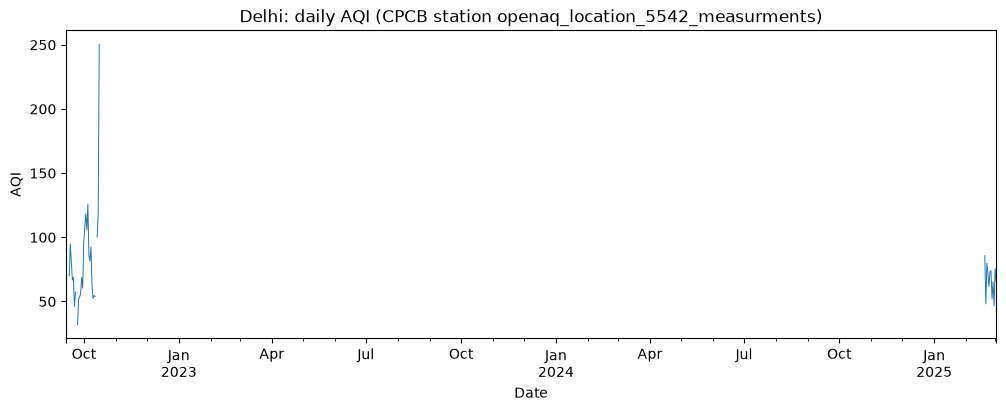

Date
1       NaN
2      66.0
3      71.0
4       NaN
5       NaN
6       NaN
7       NaN
8       NaN
9      63.0
10    101.0
11      NaN
12      NaN
Name: AQI, dtype: float64


In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 4))
poll_out["AQI"].plot(ax=ax, lw=0.7)
ax.set_title(f"{CITY}: daily AQI (CPCB station {f.stem})"); ax.set_ylabel("AQI")
plt.show()
print(poll_out["AQI"].groupby(poll_out.index.month).mean().round(0))

**What to expect:** high AQI in Oct-Jan (stubble burning, Diwali, cold still air) and low values in Jul-Sep (monsoon).

**For your report:** this is real *ground-station* data from a CPCB monitor (via OpenAQ), which is better than modelled data. The limits: it is one station, not the whole city, and sensors have gaps.